# Snow Loads
**ASCE 7-22 Chapter 7 · IBC 2024**

Flat and sloped roof snow loads using ASCE 7-22 strength-level ground snow loads (no snow
importance factor), thermal factor from Table 7.3-3, slope factor from Fig. 7.4-1, minimum
roof snow load, rain-on-snow surcharge, unbalanced gable/hip loads, leeward and windward roof
step drifts with winter wind parameter W2, and sliding snow.

**How to use:** Run the **Engine** cell once, edit the form fields below, and run **Runtime → Run all** (`Ctrl+F9` / `⌘F9`). Get pg and W2 for your Risk Category from the ASCE 7 Hazard Tool.

> Design aid only. A licensed engineer must verify all inputs and results.

In [1]:
#@title Engine — run this cell first (embedded structcalc library) { display-mode: "form" }
# Unpacks the embedded structcalc library and imports it (no pip install or Drive mount needed).
# Source: structural-calculations (lib/structcalc). Rebuild notebooks with: python build.py
import base64 as _b64, io as _io, os as _os, sys as _sys, tempfile as _tf, zipfile as _zf
_ZIP = (
    "..."
)
_dir = _os.path.join(_tf.gettempdir(), "structcalc_476d0793fd")
if not _os.path.isdir(_os.path.join(_dir, "structcalc")):
    _zf.ZipFile(_io.BytesIO(_b64.b64decode(_ZIP))).extractall(_dir)
for _m in [m for m in _sys.modules if m == "structcalc" or m.startswith("structcalc.")]:
    del _sys.modules[_m]
if _dir not in _sys.path:
    _sys.path.insert(0, _dir)
import structcalc
print(f"structcalc {structcalc.__version__} ready (build 476d0793fd)")

structcalc 0.1.0 ready (build 476d0793fd)


In [2]:
#@title 1. Site
pg = 30.0  #@param {type:"number"}
W2 = 0.55  #@param {type:"number"}
risk_category = "II"  #@param ["I", "II", "III", "IV"]
terrain = "C"  #@param ["B", "C", "D", "Above tree line (windswept mountains)", "Alaska, no trees within 2 mi"]
exposure = "Partially exposed"  #@param ["Fully exposed", "Partially exposed", "Sheltered"]
#@markdown pg in psf (strength level, Risk Category specific). W2 = winter wind parameter (about 0.25 to 0.65).

In [3]:
#@title 2. Roof
thermal = "Heated, unventilated roof (Table 7.3-3)"  #@param ["Heated, unventilated roof (Table 7.3-3)", "Kept just above freezing / cold ventilated roof", "Unheated or open air", "Freezer building", "Continuously heated greenhouse"]
roof_R_value = 30.0  #@param {type:"number"}
roof_type = "Flat"  #@param ["Flat", "Monoslope", "Gable", "Hip"]
roof_slope_deg = 0.0  #@param {type:"number"}
slippery_surface = False  #@param {type:"boolean"}
eave_to_ridge_ft = 20.0  #@param {type:"number"}
short_prismatic_rafters = False  #@param {type:"boolean"}
#@markdown *short_prismatic_rafters*: simply supported prismatic members from eave to ridge with W <= 20 ft (7.6.1 simplified unbalanced case).

In [4]:
#@title 3. Roof step drift (lower roof)
include_drift = True  #@param {type:"boolean"}
upper_roof_length_ft = 100.0  #@param {type:"number"}
lower_roof_length_ft = 40.0  #@param {type:"number"}
step_height_ft = 10.0  #@param {type:"number"}
#@markdown Upper roof length = leeward fetch; lower roof length = windward fetch, both measured in the drift direction.

In [5]:
#@title 4. Sliding snow from an upper sloped roof
include_sliding = False  #@param {type:"boolean"}
upper_roof_slope_deg = 26.57  #@param {type:"number"}
upper_eave_to_ridge_ft = 20.0  #@param {type:"number"}
upper_slippery = False  #@param {type:"boolean"}

In [6]:
#@title 5. Calculate
from structcalc.calcs import snow_loads

out = snow_loads.run(
    pg=pg, W2=W2, risk_category=risk_category, terrain=terrain, exposure=exposure,
    thermal=thermal, R_value=roof_R_value, roof_type=roof_type, theta=roof_slope_deg,
    slippery=slippery_surface, eave_to_ridge=eave_to_ridge_ft,
    prismatic_short=short_prismatic_rafters, drift=include_drift,
    upper_len=upper_roof_length_ft, lower_len=lower_roof_length_ft, step_h=step_height_ft,
    sliding=include_sliding, upper_theta=upper_roof_slope_deg,
    upper_eave_to_ridge=upper_eave_to_ridge_ft, upper_slippery=upper_slippery,
)
out["report"].show()

"Ground snow load pg Risk Category II, ASCE 7 Hazard Tool",30,psf
Winter wind parameter W2,0.55,
Terrain / exposure,C / Partially exposed,
Thermal condition,"Heated, unventilated roof (Table 7.3-3)",
Roof R-value,30,h·ft²·°F/Btu
Roof type,Flat,
Roof slope,0,deg
Slippery unobstructed surface,No,
Eave to ridge distance W,20,ft
Upper roof length (leeward fetch),100,ft
Lower roof length (windward fetch),40,ft


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


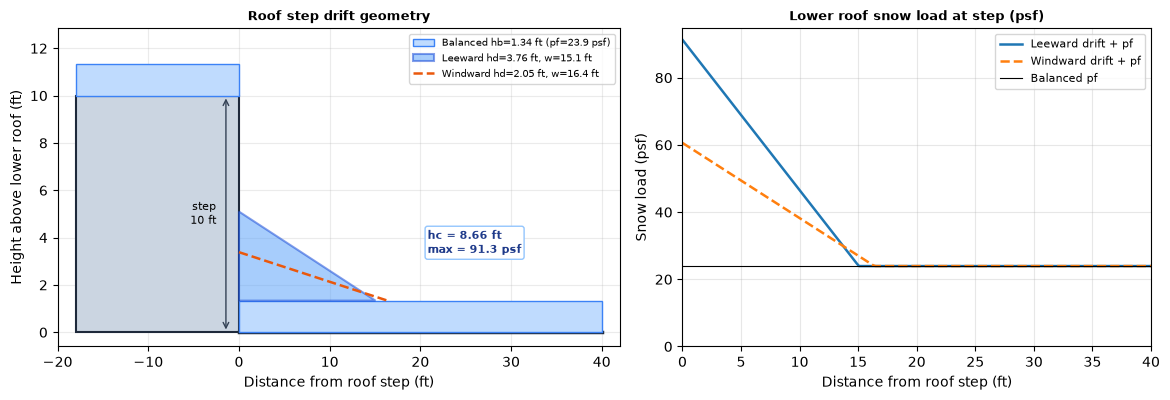

In [7]:
#@title 6. Roof snow geometry and drift surcharge plot
fig = snow_loads.plot(out, lower_roof_length_ft)

In [8]:
#@title 7. Save report as HTML (optional)
save_report = False  #@param {type:"boolean"}
if save_report:
    path = out["report"].save_html("snow_loads.html")
    print("saved", path)
    try:
        from google.colab import files
        files.download(path)
    except ImportError:
        pass